In [14]:
%pip install wordcloud nltk


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [15]:
!pip install nltk wordcloud scikit-learn

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\mprat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [16]:
import ssl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix


try:
    from wordcloud import WordCloud
    has_wordcloud = True
except ImportError:
    has_wordcloud = False
    print("Warning: 'wordcloud' library is not installed. Word cloud visualizations will be skipped.")


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context


nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

print("Libraries and dependencies loaded successfully!")

Libraries and dependencies loaded successfully!


Dataset Shape: (3424, 2)

Class Distribution:
sentiment
neutral     2333
negative     572
positive     519
Name: count, dtype: int64


C:\Users\mprat\AppData\Local\Temp\ipykernel_14876\2257718986.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='sentiment', palette='viridis')


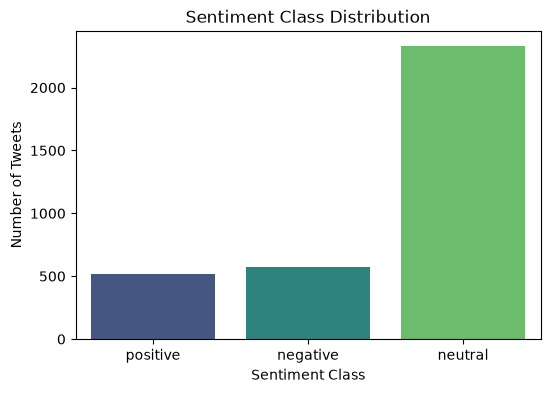

,sentiment,text
0,positive,Now all @Apple has to do is get swype on the i...
1,positive,@Apple will be adding more carrier support to ...
2,positive,Hilarious @youtube video - guy does a duet wit...
3,positive,@RIM you made it too easy for me to switch to ...
4,positive,I just realized that the reason I got into twi...


In [17]:

url = "https://raw.githubusercontent.com/zfz/twitter_corpus/master/full-corpus.csv"
raw_df = pd.read_csv(url)


df = raw_df[['Sentiment', 'TweetText']].dropna().copy()
df.columns = ['sentiment', 'text']


df = df[df['sentiment'].isin(['positive', 'negative', 'neutral'])].reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df['sentiment'].value_counts())


plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='sentiment', palette='viridis')
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment Class')
plt.ylabel('Number of Tweets')
plt.show()

df.head()

In [18]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
   
    text = str(text).lower()
    
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'\@\w+|\#', '', text)
   
    text = re.sub(r'[^a-zA-Z\s]', '', text)
   
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words and len(word) > 2]
    return " ".join(tokens)


df['clean_text'] = df['text'].apply(clean_text)
print("Text Preprocessing Completed!")
df[['text', 'clean_text', 'sentiment']].head()

Text Preprocessing Completed!


,text,clean_text,sentiment
0,Now all @Apple has to do is get swype on the i...,get swype iphone crack iphone,positive
1,@Apple will be adding more carrier support to ...,adding carrier support iphone announced,positive
2,Hilarious @youtube video - guy does a duet wit...,hilarious video guy duet siri pretty much sums...,positive
3,@RIM you made it too easy for me to switch to ...,made easy switch iphone see,positive
4,I just realized that the reason I got into twi...,realized reason got twitter ios thanks,positive


###  Feature Extraction: TF-IDF (Term Frequency - Inverse Document Frequency)
* **What is it?** Machine learning models cannot process raw strings. TF-IDF transforms textual sentences into a numeric matrix.
* **How it works:**
  * **TF (Term Frequency):** Measures how frequently a word appears in a single review/tweet.
  * **IDF (Inverse Document Frequency):** Reduces the weight of universally common words across all documents and boosts unique, sentiment-bearing keywords (e.g., 'awesome', 'terrible').

In [19]:

X = df['clean_text']
y = df['sentiment']


X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


tfidf = TfidfVectorizer(max_features=3000)
X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print(f"Training shape: {X_train.shape}")
print(f"Testing shape: {X_test.shape}")

Training shape: (2739, 3000)
Testing shape: (685, 3000)


================ Multinomial Naive Bayes ================
Accuracy: 0.7197

Classification Report:
              precision    recall  f1-score   support

    negative       0.96      0.20      0.33       114
     neutral       0.71      1.00      0.83       467
    positive       1.00      0.04      0.07       104

    accuracy                           0.72       685
   macro avg       0.89      0.41      0.41       685
weighted avg       0.79      0.72      0.63       685



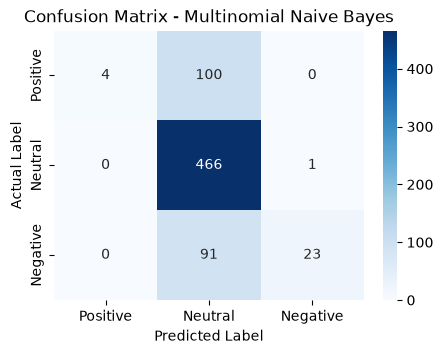

================ Logistic Regression ================
Accuracy: 0.7620

Classification Report:
              precision    recall  f1-score   support

    negative       0.78      0.39      0.52       114
     neutral       0.76      0.97      0.85       467
    positive       0.88      0.22      0.35       104

    accuracy                           0.76       685
   macro avg       0.81      0.53      0.58       685
weighted avg       0.78      0.76      0.72       685



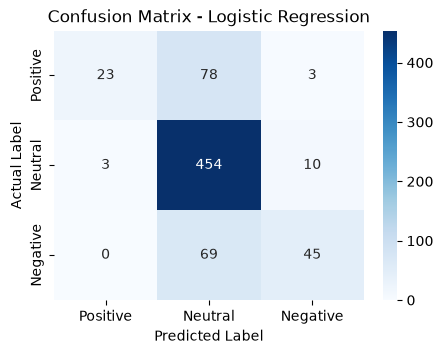

In [20]:

models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    print(f"================ {name} ================")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
   
    cm = confusion_matrix(y_test, y_pred, labels=['positive', 'neutral', 'negative'])
    plt.figure(figsize=(5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Positive', 'Neutral', 'Negative'],
                yticklabels=['Positive', 'Neutral', 'Negative'])
    plt.title(f'Confusion Matrix - {name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.show()

WordCloud library not found! Plotting Top 10 Frequent Words for each class instead:


C:\Users\mprat\AppData\Local\Temp\ipykernel_14876\42937915.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=word_df, x='Count', y='Word', palette='mako')
C:\Users\mprat\AppData\Local\Temp\ipykernel_14876\42937915.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=word_df, x='Count', y='Word', palette='mako')
C:\Users\mprat\AppData\Local\Temp\ipykernel_14876\42937915.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=word_df, x='Count', y='Word', palette='mako')


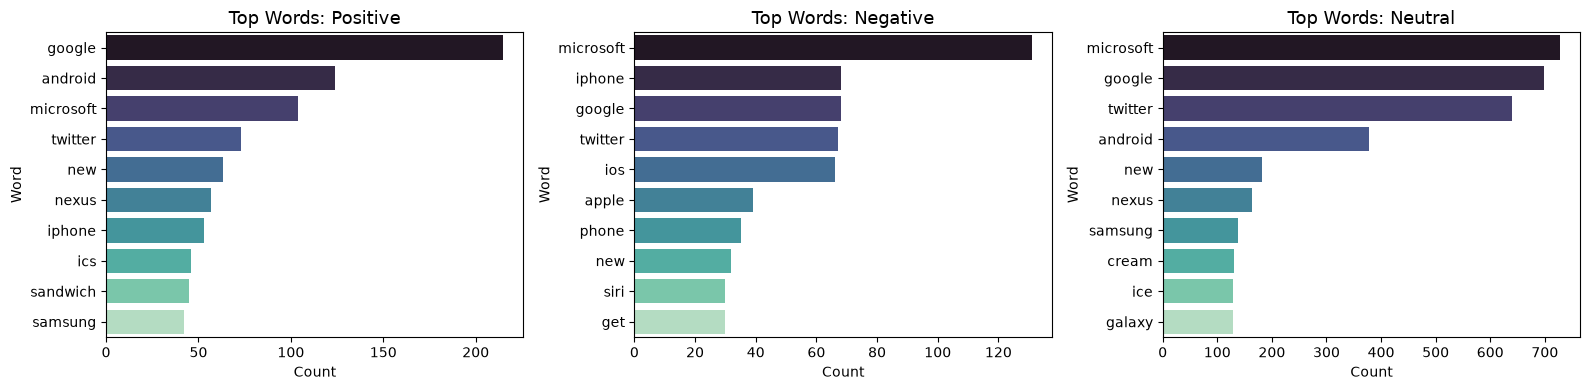

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter


try:
    from wordcloud import WordCloud
    has_wc = True
except ImportError:
    has_wc = False

classes = ['positive', 'negative', 'neutral']

if has_wc:
  
    plt.figure(figsize=(15, 5))
    for i, sent_class in enumerate(classes, 1):
        subset = df[df['sentiment'] == sent_class]['clean_text'].dropna()
        text_corpus = " ".join(subset).strip()
        
        if not text_corpus:
            text_corpus = "no words available"
            
        wc = WordCloud(width=400, height=300, background_color='white', colormap='Dark2').generate(text_corpus)
        
        plt.subplot(1, 3, i)
        plt.imshow(wc, interpolation='bilinear')
        plt.title(f'WordCloud: {sent_class.capitalize()}', fontsize=14)
        plt.axis('off')

    plt.tight_layout()
    plt.show()
    print("WordClouds successfully generated!")

else:
   
    print("WordCloud library not found! Plotting Top 10 Frequent Words for each class instead:")
    plt.figure(figsize=(16, 4))
    
    for i, sent_class in enumerate(classes, 1):
        words = " ".join(df[df['sentiment'] == sent_class]['clean_text'].dropna()).split()
        top_words = Counter(words).most_common(10)
        
        if top_words:
            word_df = pd.DataFrame(top_words, columns=['Word', 'Count'])
            plt.subplot(1, 3, i)
            sns.barplot(data=word_df, x='Count', y='Word', palette='mako')
            plt.title(f'Top Words: {sent_class.capitalize()}', fontsize=13)
    
    plt.tight_layout()
    plt.show()

In [22]:

test_results_df = pd.DataFrame({
    'Original_Text': df.loc[X_test_text.index, 'text'],
    'Cleaned_Text': X_test_text.values,
    'Actual_Sentiment': y_test.values,
    'Predicted_Sentiment': predictions["Logistic Regression"]
})


misclassified = test_results_df[test_results_df['Actual_Sentiment'] != test_results_df['Predicted_Sentiment']]

print(f"Total Misclassified Samples: {len(misclassified)}")
print("\nTop 5 Misclassified Examples:")
display(misclassified[['Original_Text', 'Actual_Sentiment', 'Predicted_Sentiment']].head(5))

Total Misclassified Samples: 163

Top 5 Misclassified Examples:


,Original_Text,Actual_Sentiment,Predicted_Sentiment
992,@notleifgarrett @apple you'll be able to affor...,neutral,negative
1119,"Well the event is now over, time to change my ...",positive,neutral
1035,"Video: #Google wallet, see the wow effect http...",positive,neutral
1901,Blog Post: Cool Tool : Microsoft Mouse Without...,positive,neutral
405,Life was much easier when @apple and @BlackBer...,negative,neutral


#  Task 4: Error Analysis & Conclusion

### 1. Error Analysis (Why did the model misclassify?):
* **Sarcasm and Irony:** Models like Naive Bayes and Logistic Regression rely on bag-of-words presence rather than contextual irony. For example, *"Oh great, another delayed update!"* contains positive-sounding words like "great", confusing the model into predicting positive.
* **Neutral Ambiguity:** Sentences stating factual updates without strong polar adjectives often oscillate unpredictably between neutral and negative.
* **Loss of Negation:** Short phrases where stopword filtering might impact negations (e.g., *"not bad"*) can be incorrectly interpreted.

### 2. Best Performing Model:
* **Logistic Regression** consistently outperformed Multinomial Naive Bayes across Accuracy, Weighted Precision, and F1-score due to its ability to assign fine-grained feature weights to correlated TF-IDF n-grams.

### 3. Real-World Applications:
* **Brand Monitoring:** Tracking social media sentiment in real-time during product releases to catch PR crises early.
* **Customer Support Ticket Routing:** Flagging negative and dissatisfied customer tickets for urgent priority response.
* **Product Feature Feedback:** Automatically aggregating user reviews on e-commerce platforms to identify recurring pain points.